# Goods receipts — fréquence des réceptions et attentes qualité
**G05 — contribution Merieme.** Une ligne = une réception ; on étudie des nombres d'événements et la proportion de réceptions `quality_hold`.
Les quantités physiques ne sont pas sommées entre unités différentes. Les tables des collègues et le notebook de nettoyage restent inchangés.

**Méthodes :** IQR/Z/Z modifié du groupe, appliqués aux nombres mensuels par établissement. Compléments justifiés : test binomial conditionnel pour les pics de fréquence, test exact de Fisher pour comparer les taux, intervalles de Wilson et correction Benjamini–Hochberg (BH). Ils évitent de traiter 1 blocage sur 2 réceptions comme aussi fiable que 50 sur 100.
Pas de modèle IF/LOF imposant un quota sur ces comptes très discrets et ces taux à dénominateurs variables.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import binom, fisher_exact
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
import sklearn, scipy, sys

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'data/data_dictionary.csv').exists()), None)
assert ROOT is not None, "Lancer le notebook depuis le dépôt."
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': .2,
                     'font.size': 10, 'figure.dpi': 100})
pd.set_option('display.max_columns', 18)
pd.set_option('display.max_rows', 25)
print('Versions :', sys.version.split()[0], 'pandas', pd.__version__,
      'numpy', np.__version__, 'scikit-learn', sklearn.__version__, 'scipy', scipy.__version__)

def lecture(nom, domaine, cle):
    raw = pd.read_csv(ROOT / 'data' / domaine / (nom + '.csv'))
    path = ROOT / 'data' / domaine / 'cleaned' / (nom + '_cleaned.csv')
    clean = pd.read_csv(path)
    display(pd.DataFrame({'source': ['brut', 'nettoyé'],
                          'lignes': [len(raw), len(clean)],
                          'colonnes': [raw.shape[1], clean.shape[1]],
                          'doublons_exacts': [raw.duplicated().sum(), clean.duplicated().sum()],
                          'doublons_cle': [raw.duplicated(cle).sum(), clean.duplicated(cle).sum()]}))
    display(pd.DataFrame({'type': clean.dtypes.astype(str), 'manquants': clean.isna().sum()}))
    assert clean[cle].notna().all() and clean[cle].is_unique, "Clé primaire à vérifier."
    return raw, clean

def statistiques(data, cle, variables, groupes=(), min_n=8, haut_seul=False):
    """Comparaisons rétrospectives au sein de groupes homogènes ; aucune imputation."""
    records = []
    grouped = data.groupby(list(groupes), dropna=False, sort=True) if groupes else [('ensemble', data)]
    for key, group in grouped:
        if groupes:
            keys = key if isinstance(key, tuple) else (key,)
            label = '; '.join(f'{c}={v}' for c, v in zip(groupes, keys))
        else:
            label = 'ensemble'
        for variable in variables:
            x = pd.to_numeric(group[variable], errors='raise').replace([np.inf, -np.inf], np.nan)
            good = x.dropna()
            n = len(good)
            q1, q3 = good.quantile([.25, .75]) if n else (np.nan, np.nan)
            iqr, mean, sd = q3 - q1, good.mean(), good.std(ddof=1)
            med = good.median()
            mad = (good - med).abs().median()
            specs = [
                ('IQR', q1-1.5*iqr, q3+1.5*iqr, x, iqr, 'hors Q1−1.5×IQR ; Q3+1.5×IQR'),
                ('Z-score', mean-3*sd, mean+3*sd, (x-mean)/sd if sd > 0 else x*0+np.nan, sd, '|z| > 3'),
                ('Z-modifie', med-3.5*mad/.6745, med+3.5*mad/.6745,
                 .6745*(x-med)/mad if mad > 0 else x*0+np.nan, mad, '|z_mod| > 3.5'),
            ]
            for method, lo, hi, scores, spread, rule in specs:
                usable = n >= min_n and pd.notna(spread) and spread > 1e-12
                if haut_seul: lo = -np.inf; rule += ' (queue haute uniquement)'
                for idx in group.index:
                    available = bool(usable and pd.notna(x.loc[idx]))
                    flag = bool(available and (x.loc[idx] < lo or x.loc[idx] > hi))
                    records.append({
                        'observation': str(group.at[idx, cle]), 'groupe': label,
                        'variable': variable, 'methode': method, 'valeur': x.loc[idx],
                        'score': scores.loc[idx] if available else np.nan,
                        'borne_basse': lo if usable else np.nan, 'borne_haute': hi if usable else np.nan,
                        'n_reference': n, 'applicable': available, 'signalee': flag,
                        'regle': rule if usable else f'Non évalué : n < {min_n} ou dispersion nulle',
                        'interpretation': 'Valeur atypique dans ce groupe ; contrôle du contexte nécessaire, pas une erreur établie.'
                    })
    return pd.DataFrame(records)

def resume_tests(tests):
    display(tests.groupby(['variable', 'methode']).agg(
        evaluations=('applicable', 'sum'), signalees=('signalee', 'sum')).reset_index())
    skipped = tests.loc[~tests.applicable, ['groupe','variable','methode','regle']].drop_duplicates()
    if len(skipped):
        print('Cas non évalués (extrait) :'); display(skipped.head(12))

def bh(pvalues):
    """Benjamini–Hochberg : ajustement descriptif des comparaisons multiples."""
    pvalues = np.asarray(pvalues, dtype=float)
    result = np.full(len(pvalues), np.nan)
    good = np.flatnonzero(np.isfinite(pvalues))
    if len(good):
        order = good[np.argsort(pvalues[good])]
        adjusted = pvalues[order] * len(good) / np.arange(1, len(good)+1)
        result[order] = np.minimum.accumulate(adjusted[::-1])[::-1].clip(0,1)
    return result

def wilson(k, n, z=1.96):
    k, n = np.asarray(k, float), np.asarray(n, float)
    rate = k/n; den = 1+z*z/n
    center = (rate+z*z/(2*n))/den
    half = z*np.sqrt(rate*(1-rate)/n+z*z/(4*n*n))/den
    # Les bornes exactes k=0/k=n évitent les erreurs d'arrondi à 1e-17.
    low = np.where(k == 0, 0., np.clip(center-half, 0, 1))
    high = np.where(k == n, 1., np.clip(center+half, 0, 1))
    return low, high

def frequences(data, facility, date):
    """Panel entre premier et dernier mois observés, y compris les zéros enregistrés."""
    frames = []
    for name, g in data.groupby(facility):
        periods = g[date].dt.to_period('M')
        grid = pd.period_range(periods.min(), periods.max(), freq='M')
        counts = periods.value_counts().reindex(grid, fill_value=0).sort_index()
        out = pd.DataFrame({'etablissement':name, 'mois':grid.to_timestamp(), 'n':counts.values})
        # Bords exclus : premier/dernier mois d'activité observée potentiellement incomplets.
        out['interieur'] = (np.arange(len(out)) > 0) & (np.arange(len(out)) < len(out)-1)
        out['historique_12'] = out['n'].shift(1).rolling(12, min_periods=12).sum()
        past_complete = out['interieur'].shift(1).rolling(12, min_periods=12).sum().eq(12)
        out['eligible'] = out['interieur'] & past_complete
        out['p_pic'] = np.nan
        ix = out['eligible']
        # Sous un taux constant, conditionnellement au total, le mois testé représente 1/13 de l'exposition.
        total = (out.loc[ix,'historique_12']+out.loc[ix,'n']).astype(int)
        out.loc[ix,'p_pic'] = binom.sf(out.loc[ix,'n']-1, total, 1/13)
        out['observation'] = str(name)+'|'+out['mois'].dt.strftime('%Y-%m')
        frames.append(out)
    out = pd.concat(frames, ignore_index=True)
    out['q_pic'] = bh(out.p_pic)
    out['pic_BH'] = out.q_pic.lt(.05)
    return out

def test_pics(panel):
    result = pd.DataFrame({
        'observation': panel.observation, 'groupe':panel.etablissement,
        'variable':'nombre_mensuel', 'methode':'Binomial_conditionnel_BH',
        'valeur': panel.n, 'score':panel.q_pic,
        'historique_12':panel.historique_12, 'p_brut':panel.p_pic,
        'borne_basse':0., 'borne_haute':.05, 'n_reference':12,
        'applicable':panel.eligible, 'signalee':panel.pic_BH,
        'regle':'q_BH < 0.05 ; comparaison aux 12 mois précédents, bords exclus',
        'interpretation':"Pic exploratoire sous hypothèse de taux constant et couverture continue ; vérifier collecte et saisonnalité."
    })
    return result

def bilan(tests, nom, domaine):
    """Conserve toutes les détections avec leur méthode ; une ligne peut être signalée plusieurs fois."""
    tests = tests.copy()
    tests['echelle_seuil'] = np.where(tests.methode.isin(['Binomial_conditionnel_BH','Fisher_exact_BH','IF','LOF','LOF_k5']), 'score', 'valeur')
    flagged = tests.loc[tests.signalee].copy()
    output = ROOT / 'data' / domaine / 'syntheses'
    output.mkdir(parents=True, exist_ok=True)
    flagged.to_csv(output / (nom+'_anomalies.csv'), index=False)
    # Les bornes restent interprétables avec variable, méthode et effectif de référence.
    cols = ['groupe','variable','methode','borne_basse','borne_haute','n_reference','regle','echelle_seuil']
    tests[cols].drop_duplicates().to_csv(output / (nom+'_seuils.csv'), index=False)
    assert flagged.observation.notna().all()
    print(f'{len(flagged)} détections ; {flagged.observation.nunique()} identifiants distincts (unités d’analyse précisées dans le notebook).')
    display(flagged.head(20))
    return flagged


Versions : 3.9.6 pandas 2.3.3 numpy 2.0.2 scikit-learn 1.6.1 scipy 1.13.1


## 1. Audit et définition des indicateurs
Les inspections manquantes restent inconnues. Le statut de réception, renseigné, définit l'attente qualité ; on ne déduit pas ce statut de l'inspection. Les dates servent à grouper les événements, jamais comme nombres arbitraires dans un modèle.

In [2]:
raw,df=lecture('goods_receipts','logistics','receipt_number')
df['receipt_date']=pd.to_datetime(df.receipt_date,errors='raise')
df['received_quantity']=pd.to_numeric(df.received_quantity,errors='raise')
assert df.receipt_date.notna().all() and df.received_quantity.gt(0).all()
assert df.receipt_status.notna().all()
display(df.receipt_status.value_counts(dropna=False))
display(pd.crosstab(df.inspection_status.fillna('[non renseigné]'),df.receipt_status))
df['quality_hold']=df.receipt_status.eq('quality_hold')
df['month']=df.receipt_date.dt.to_period('M')
df['quarter']=df.receipt_date.dt.to_period('Q')
global_rate=df.quality_hold.mean()
print('Période :',df.receipt_date.min().date(),'→',df.receipt_date.max().date())
print(f'Attentes qualité : {df.quality_hold.sum()} / {len(df)} = {global_rate:.2%}')


,source,lignes,colonnes,doublons_exacts,doublons_cle
0,brut,612,12,2,2
1,nettoyé,610,12,0,0


,type,manquants
receipt_number,object,0
purchase_order_number,object,0
purchase_order_line,int64,0
receipt_date,object,0
receiving_facility_code,object,0
supplier_partner_code,object,0
received_quantity,float64,0
received_unit,object,0
batch_reference,object,0
inspection_status,object,4


receipt_status
posted          576
quality_hold     34
Name: count, dtype: int64

receipt_status,posted,quality_hold
inspection_status,,
[non renseigné],4,0
accepted,505,0
conditional,67,0
held,0,34


Période : 2014-07-08 → 2025-06-30
Attentes qualité : 34 / 610 = 5.57%


## 2. Volumes et taux descriptifs
La fréquence mesure les événements enregistrés dans le fichier, pas la capacité d'un établissement. Une couverture temporelle différente ou un rôle de plateforme logistique peut expliquer des volumes élevés.

,n,held,rate,low,high
receiving_facility_code,,,,,
FCL-1011,133,5,0.037594,0.016163,0.084988
FCL-1007,76,4,0.052632,0.020655,0.127659
FCL-1010,61,5,0.081967,0.035519,0.177949
FCL-1019,54,3,0.055556,0.019073,0.151075
FCL-1030,37,5,0.135135,0.059132,0.279777
...,...,...,...,...,...
FCL-1027,4,0,0.000000,0.000000,0.489900
FCL-1028,4,0,0.000000,0.000000,0.489900
FCL-1021,3,0,0.000000,0.000000,0.561506


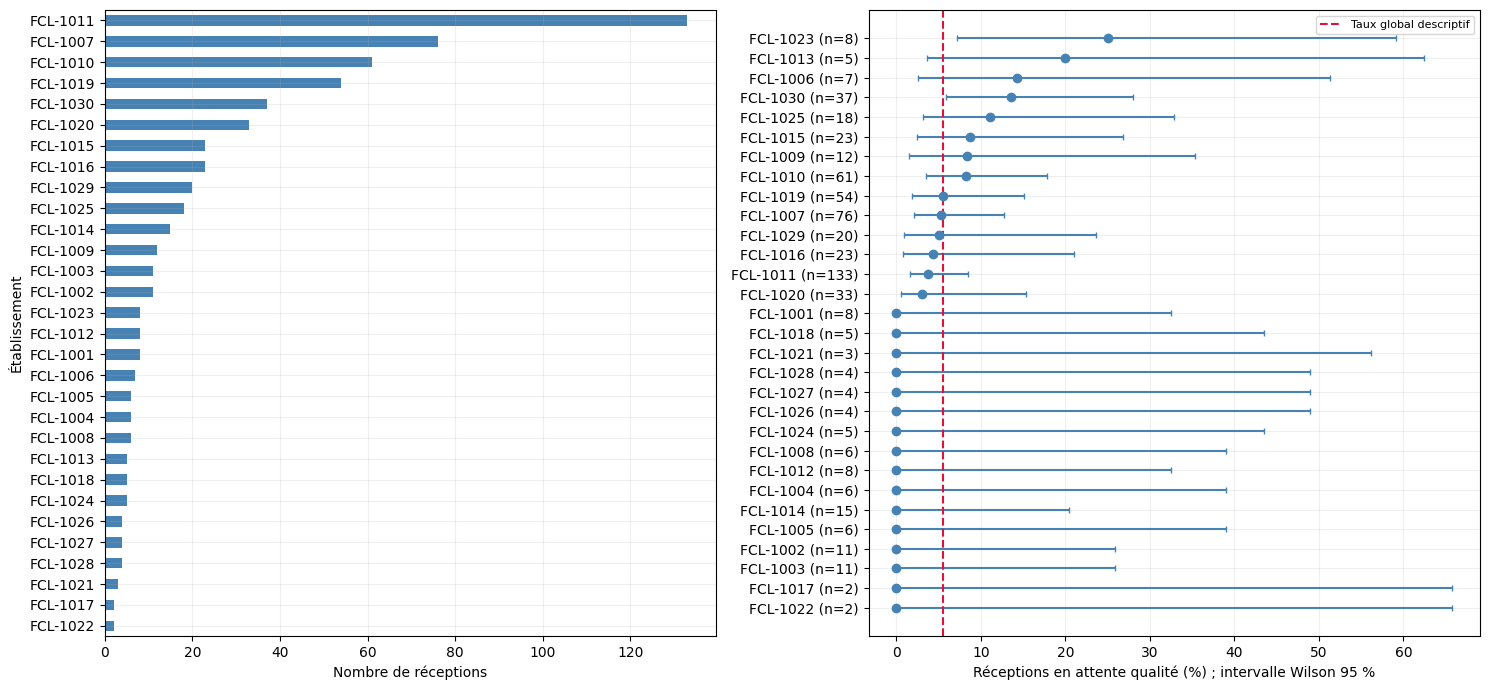

**Lecture :** les intervalles larges exposent l'incertitude des petits effectifs. La ligne globale est un repère ; le test ci-dessous compare chaque établissement aux autres, sans l'inclure dans sa propre référence.

In [3]:
facility=df.groupby('receiving_facility_code').agg(n=('receipt_number','size'),held=('quality_hold','sum'))
facility['rate']=facility.held/facility.n
facility['low'],facility['high']=wilson(facility.held,facility.n)
facility=facility.sort_values('n',ascending=False)
display(facility)
fig,axes=plt.subplots(1,2,figsize=(15,7))
facility.n.sort_values().plot.barh(ax=axes[0],color='steelblue')
axes[0].set_xlabel('Nombre de réceptions');axes[0].set_ylabel('Établissement')
ordered=facility.sort_values('rate')
pos=np.arange(len(ordered))
axes[1].errorbar(100*ordered.rate,pos,
    xerr=np.vstack([100*(ordered.rate-ordered.low),100*(ordered.high-ordered.rate)]),
    fmt='o',capsize=2,color='steelblue')
axes[1].set_yticks(pos,[f'{idx} (n={n})' for idx,n in zip(ordered.index,ordered.n)])
axes[1].axvline(global_rate*100,c='crimson',ls='--',label='Taux global descriptif')
axes[1].set_xlabel('Réceptions en attente qualité (%) ; intervalle Wilson 95 %')
axes[1].legend(fontsize=8);fig.tight_layout();plt.show()
display(Markdown("**Lecture :** les intervalles larges exposent l'incertitude des petits effectifs. La ligne globale est un repère ; le test ci-dessous compare chaque établissement aux autres, sans l'inclure dans sa propre référence."))


## 3. Évolution temporelle
Le graphique mensuel inclut tous les mois de la période globale, y compris ceux sans réception enregistrée. Les taux trimestriels ont leur dénominateur affiché dans le tableau. Un trimestre sans réception n'a pas de taux : il reste manquant. Les périodes de début/fin peuvent être partielles.

,n,held,rate,low,high
2022Q3,3,0,0.000000,0.000000,0.561506
2022Q4,30,2,0.066667,0.018477,0.213238
2023Q1,11,0,0.000000,0.000000,0.258840
2023Q2,39,4,0.102564,0.040613,0.235792
2023Q3,13,1,0.076923,0.013710,0.333145
2023Q4,34,3,0.088235,0.030465,0.229608
2024Q1,7,1,0.142857,0.025679,0.513135
2024Q2,12,0,0.000000,0.000000,0.242501
2024Q3,33,2,0.060606,0.016781,0.196066
2024Q4,8,0,0.000000,0.000000,0.324416


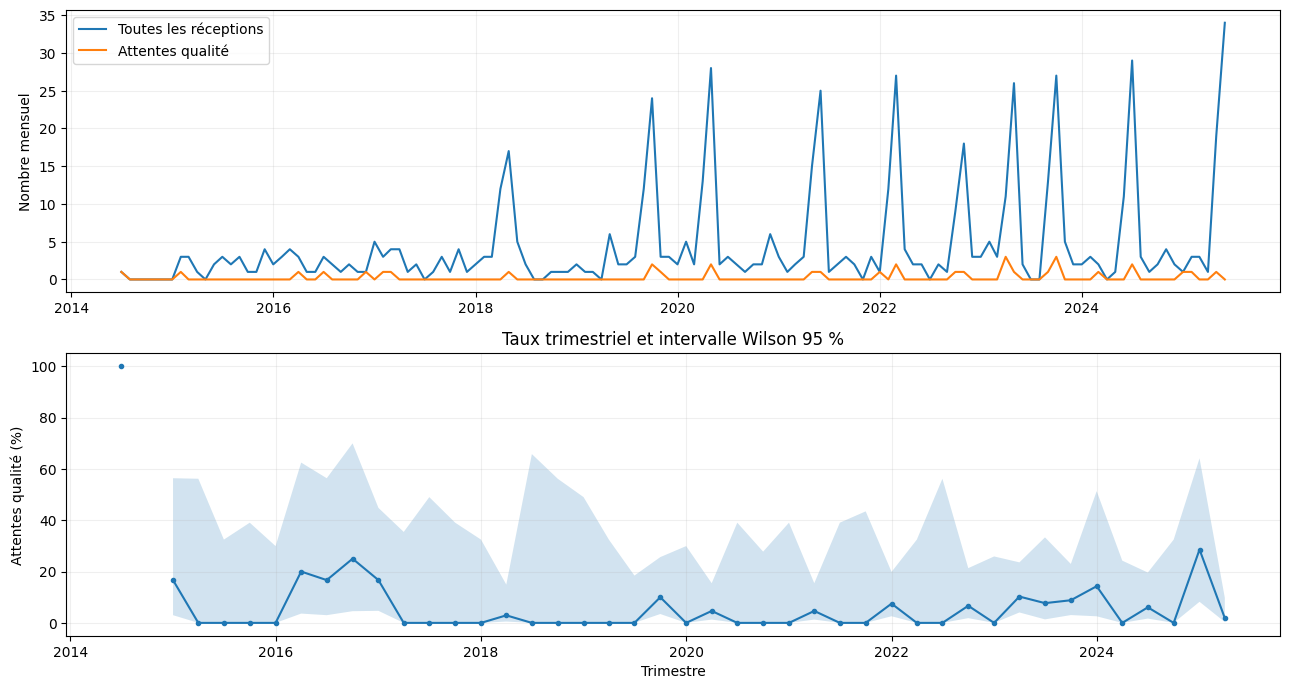

In [4]:
months=pd.period_range(df.month.min(),df.month.max(),freq='M')
monthly=df.groupby('month').agg(n=('receipt_number','size'),held=('quality_hold','sum')).reindex(months,fill_value=0)
quarters=pd.period_range(df.quarter.min(),df.quarter.max(),freq='Q')
quarterly=df.groupby('quarter').agg(n=('receipt_number','size'),held=('quality_hold','sum')).reindex(quarters,fill_value=0)
quarterly['rate']=quarterly.held/quarterly.n.replace(0,np.nan)
quarterly['low'],quarterly['high']=wilson(quarterly.held,quarterly.n.replace(0,np.nan))
display(quarterly.tail(12))
fig,axes=plt.subplots(2,1,figsize=(13,7))
axes[0].plot(monthly.index.to_timestamp(),monthly.n,label='Toutes les réceptions')
axes[0].plot(monthly.index.to_timestamp(),monthly.held,label='Attentes qualité')
axes[0].set_ylabel('Nombre mensuel');axes[0].legend()
x=quarterly.index.to_timestamp()
axes[1].plot(x,100*quarterly.rate,marker='o',ms=3)
axes[1].fill_between(x,100*quarterly.low,100*quarterly.high,alpha=.2)
axes[1].set_ylabel('Attentes qualité (%)');axes[1].set_xlabel('Trimestre')
axes[1].set_title('Taux trimestriel et intervalle Wilson 95 %')
fig.tight_layout();plt.show()


### Qualité par établissement ET trimestre
Ce tableau combine les deux dimensions. Chaque taux conserve son nombre de blocages, son dénominateur et son intervalle de Wilson. Aucun événement enregistré donne un taux manquant, pas 0 %. La figure montre les six établissements les plus documentés sur les douze derniers trimestres ; le tableau exporté couvre toute la période.


n  held      rate       low      high
receiving_facility_code quarter                                        
FCL-1011                2019Q4    8     2  0.250000  0.071478  0.590730
                        2021Q2   10     1  0.100000  0.017876  0.404156
FCL-1010                2021Q2    8     1  0.125000  0.022417  0.470895
FCL-1007                2018Q2    6     1  0.166667  0.030053  0.563509
                        2023Q2    6     1  0.166667  0.030053  0.563509
FCL-1019                2022Q1    5     1  0.200000  0.036223  0.624472
FCL-1030                2023Q2    5     1  0.200000  0.036223  0.624472
FCL-1010                2025Q2    4     1  0.250000  0.045586  0.699364
FCL-1020                2022Q1    4     1  0.250000  0.045586  0.699364
FCL-1029                2020Q2    4     1  0.250000  0.045586  0.699364
FCL-1011                2017Q1    3     1  0.333333  0.061490  0.792345
                        2023Q4    3     1  0.333333  0.061490  0.792345
FCL-1007                2023Q4    3     1  0.333333  0.061490  0.792345
FCL-1019                2017Q1    3     1  0.333333  0.061490  0.792345
FCL-1016                2024Q3    3     1  0.333333  0.061490  0.792345

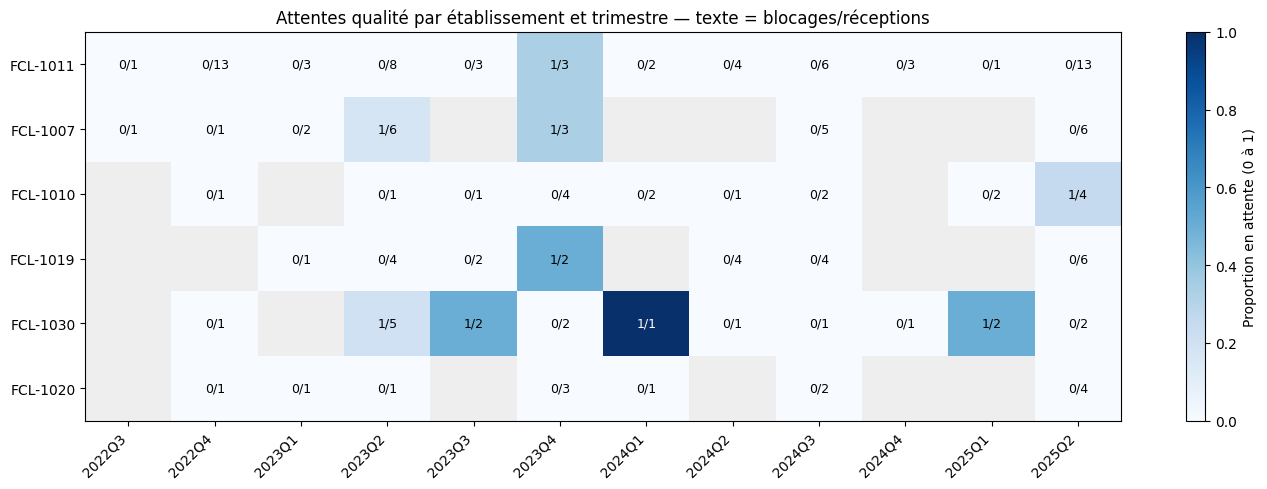

**Lecture :** une case à 100 % avec 1/1 ne documente pas le même niveau de risque que des blocages répétés sur un grand nombre de réceptions. Les zones grises ne prouvent pas une fermeture de site. Ces taux temporels restent descriptifs.

In [5]:
grid=pd.MultiIndex.from_product([facility.index, quarters],names=['receiving_facility_code','quarter'])
quality_by_period=df.groupby(['receiving_facility_code','quarter']).agg(
    n=('receipt_number','size'),held=('quality_hold','sum')).reindex(grid,fill_value=0)
quality_by_period['rate']=quality_by_period.held/quality_by_period.n.replace(0,np.nan)
quality_by_period['low'],quality_by_period['high']=wilson(quality_by_period.held,quality_by_period.n.replace(0,np.nan))
assert quality_by_period.n.sum()==len(df)
assert quality_by_period.held.sum()==df.quality_hold.sum()
display(quality_by_period.loc[quality_by_period.n.gt(0)].sort_values(['held','n'],ascending=False).head(15))
recent_quarters=quarters[-12:]
leaders=facility.head(6).index
matrix=quality_by_period.rate.unstack().reindex(index=leaders,columns=recent_quarters)
fig,ax=plt.subplots(figsize=(14,5))
im=ax.imshow(np.ma.masked_invalid(matrix.to_numpy()),vmin=0,vmax=1,cmap='Blues',aspect='auto')
ax.set_facecolor('#eeeeee')
for i,fac in enumerate(leaders):
    for j,q in enumerate(recent_quarters):
        row=quality_by_period.loc[(fac,q)]
        if row.n>0:
            ax.text(j,i,f'{int(row.held)}/{int(row.n)}',ha='center',va='center',color='white' if row.rate>.5 else 'black',fontsize=9)
ax.set_xticks(range(len(recent_quarters)),recent_quarters.astype(str),rotation=45,ha='right')
ax.set_yticks(range(len(leaders)),leaders)
ax.set_title('Attentes qualité par établissement et trimestre — texte = blocages/réceptions')
fig.colorbar(im,ax=ax,label='Proportion en attente (0 à 1)')
ax.grid(False);fig.tight_layout();plt.show()
output=ROOT/'data/logistics/syntheses'
output.mkdir(parents=True,exist_ok=True)
quality_by_period.reset_index().to_csv(output/'goods_receipts_qualite_trimestrielle.csv',index=False)
display(Markdown('**Lecture :** une case à 100 % avec 1/1 ne documente pas le même niveau de risque que des blocages répétés sur un grand nombre de réceptions. Les zones grises ne prouvent pas une fermeture de site. Ces taux temporels restent descriptifs.'))


## 4. Fréquences inhabituelles au sein des établissements
Panel mensuel entre la première et la dernière réception observées par établissement : les mois internes sans événement sont comptés zéro **sous hypothèse de couverture continue**. Cette hypothèse ne prouve pas que l'établissement était actif.
IQR/Z sont appliqués par établissement aux mois internes. Les distributions très discrètes et l'IQR/MAD souvent nuls rendent ces indicateurs exploratoires.
Pour un pic, comparaison du mois courant aux 12 mois précédents, sans utiliser les événements futurs. Sous taux constant et expositions mensuelles égales, le compte courant conditionnel au total des 13 mois suit Binomiale(total, 1/13). Correction BH sur tous les mois testés ; seuil q<0,05. Saison, durée des mois et dépendances temporelles restent des limites.

### Règles de lecture communes
IQR : bornes Q1 − 1,5×IQR et Q3 + 1,5×IQR ; Z-score : |z| > 3 ; Z modifié : 0,6745×(x−médiane)/MAD, seuil 3,5.
Ces seuils exploratoires viennent des notebooks du groupe, pas d'une vérité terrain.
Les groupes de moins de 8 observations et les dispersions nulles sont déclarés **non évaluables** : pas de division par zéro, ni de classement automatique de toute valeur non nulle comme anomalie.
Les comparaisons utilisent des groupes explicites ; elles sont rétrospectives et n'estiment pas une causalité.
Les résultats complets signalés et les seuils sont exportés uniquement dans `syntheses/`. Les fichiers bruts et nettoyés ne sont pas modifiés.


,variable,methode,evaluations,signalees
0,n,IQR,375,26
1,n,Z-modifie,0,0
2,n,Z-score,2538,96


Cas non évalués (extrait) :


,groupe,variable,methode,regle
0,etablissement=FCL-1001,n,IQR,Non évalué : n < 12 ou dispersion nulle
128,etablissement=FCL-1001,n,Z-modifie,Non évalué : n < 12 ou dispersion nulle
192,etablissement=FCL-1002,n,IQR,Non évalué : n < 12 ou dispersion nulle
390,etablissement=FCL-1002,n,Z-modifie,Non évalué : n < 12 ou dispersion nulle
489,etablissement=FCL-1003,n,IQR,Non évalué : n < 12 ou dispersion nulle
685,etablissement=FCL-1003,n,Z-modifie,Non évalué : n < 12 ou dispersion nulle
783,etablissement=FCL-1004,n,IQR,Non évalué : n < 12 ou dispersion nulle
935,etablissement=FCL-1004,n,Z-modifie,Non évalué : n < 12 ou dispersion nulle
1011,etablissement=FCL-1005,n,IQR,Non évalué : n < 12 ou dispersion nulle
1185,etablissement=FCL-1005,n,Z-modifie,Non évalué : n < 12 ou dispersion nulle


Mois testés contre historique de 12 mois : 2298
Pics p<0.05 avant correction : 53
Pics q<0.05 après correction BH : 3


,observation,n,historique_12,p_pic,q_pic,pic_BH
1061,FCL-1011|2018-05,6,0.0,2.071762e-07,0.000353,True
1098,FCL-1011|2021-06,9,6.0,3.071393e-07,0.000353,True
1107,FCL-1011|2022-03,9,14.0,2.837454e-05,0.021735,True
653,FCL-1007|2024-07,5,3.0,1.236891e-04,0.071059,False
1078,FCL-1011|2019-10,7,10.0,1.549973e-04,0.071237,False
1115,FCL-1011|2022-11,8,16.0,2.928017e-04,0.112143,False
974,FCL-1010|2021-06,5,6.0,8.378832e-04,0.275065,False
2675,FCL-1030|2023-05,4,3.0,1.013394e-03,0.291098,False
596,FCL-1007|2019-10,5,7.0,1.345414e-03,0.328542,False
1641,FCL-1016|2023-05,3,1.0,1.715626e-03,0.328542,False


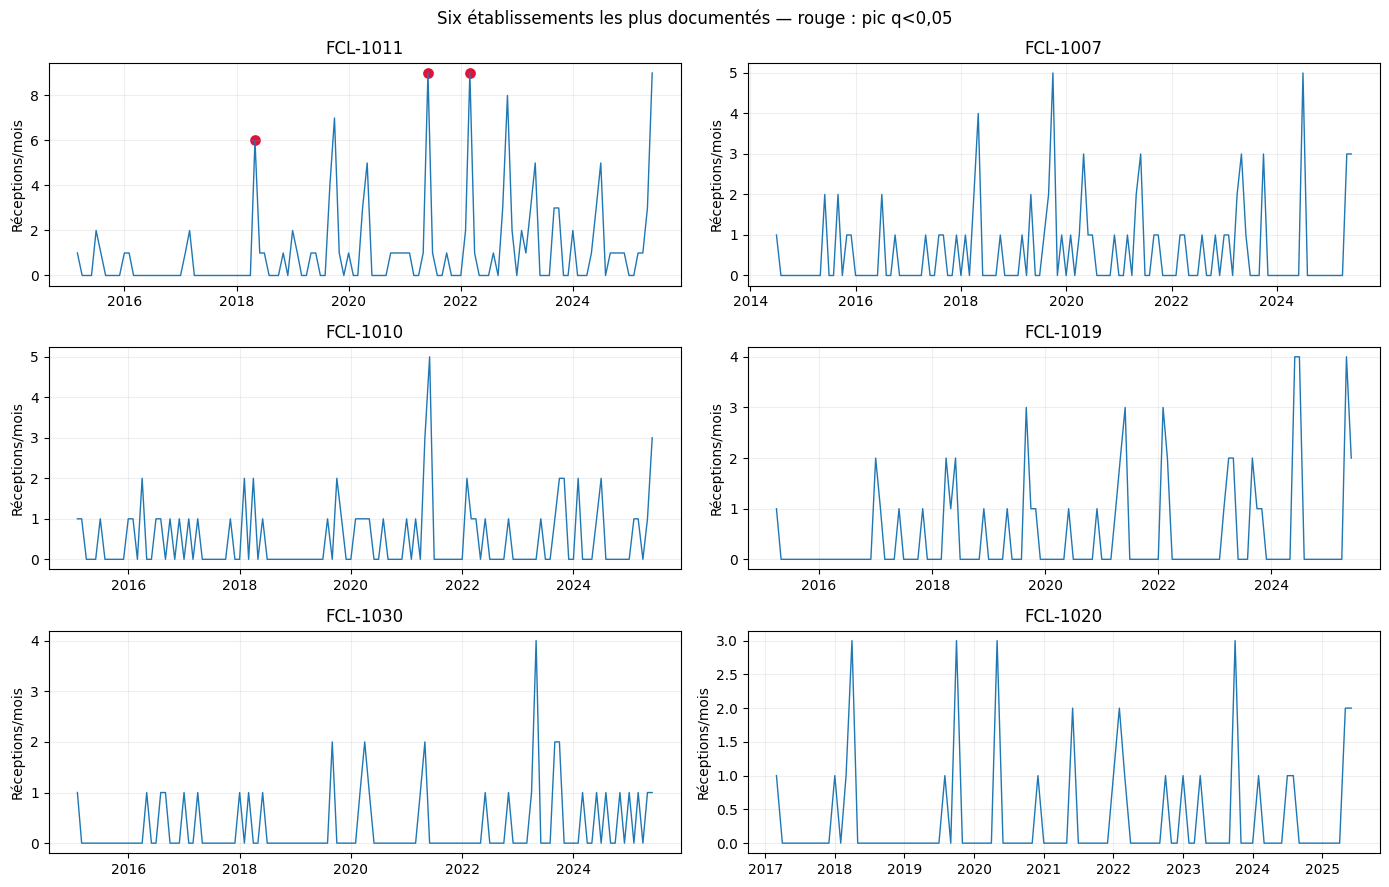

**Lecture :** le volume total élevé d'un établissement n'est pas en lui-même une anomalie. Les pics sont évalués par rapport à son historique. Les signaux IQR/Z non confirmés par le test conditionnel restent exploratoires.

In [6]:
panel=frequences(df,'receiving_facility_code','receipt_date')
interior=panel.loc[panel.interieur].copy()
tests=statistiques(interior,'observation',['n'],['etablissement'],min_n=12,haut_seul=True)
resume_tests(tests)
peaks=test_pics(panel)
print('Mois testés contre historique de 12 mois :',panel.eligible.sum())
print('Pics p<0.05 avant correction :',panel.p_pic.lt(.05).sum())
print('Pics q<0.05 après correction BH :',panel.pic_BH.sum())
display(panel.loc[panel.eligible].nsmallest(12,'q_pic')[
    ['observation','n','historique_12','p_pic','q_pic','pic_BH']])
# Chaque point agrégé peut être relié aux réceptions sources.
members=df.groupby(['receiving_facility_code','month']).receipt_number.agg(lambda x:'; '.join(x))
panel['observations_sources']=[
    members.get((f,pd.Period(m,freq='M')),'[aucune réception enregistrée]')
    for f,m in zip(panel.etablissement,panel.mois)]
top=facility.head(6).index
fig,axes=plt.subplots(3,2,figsize=(14,9))
for ax,name in zip(axes.flat,top):
    g=panel.loc[panel.etablissement.eq(name)]
    ax.plot(g.mois,g.n,lw=1)
    marked=g.pic_BH
    ax.scatter(g.loc[marked,'mois'],g.loc[marked,'n'],c='crimson',s=45)
    ax.set_title(name);ax.set_ylabel('Réceptions/mois')
fig.suptitle('Six établissements les plus documentés — rouge : pic q<0,05')
fig.tight_layout();plt.show()
display(Markdown("**Lecture :** le volume total élevé d'un établissement n'est pas en lui-même une anomalie. Les pics sont évalués par rapport à son historique. Les signaux IQR/Z non confirmés par le test conditionnel restent exploratoires."))


## 5. Établissements au taux qualité atypique
Test exact de Fisher unilatéral (taux plus élevé) : tableau 2×2 « attente/autre × établissement/autres établissements ».
Tous les établissements sont testés ; les effectifs ne sont pas masqués par une sélection arbitraire. Correction BH sur la famille des tests.
Les taux mensuels par établissement sont trop peu documentés : les variations trimestrielles sont décrites avec intervalles, sans multiplier les tests.

In [7]:
total_held=int(df.quality_hold.sum());total_n=len(df)
facility['p_fisher']=[
    fisher_exact([[int(row.held),int(row.n-row.held)],
                  [total_held-int(row.held),(total_n-int(row.n))-(total_held-int(row.held))]],
                 alternative='greater').pvalue
    for _,row in facility.iterrows()]
facility['q_fisher']=bh(facility.p_fisher)
facility['atypique']=facility.q_fisher.lt(.05)
display(facility.sort_values('rate',ascending=False))
quality_tests=pd.DataFrame({
    'observation':facility.index,'groupe':'établissement versus tous les autres',
    'variable':'taux_quality_hold','methode':'Fisher_exact_BH','valeur':facility.rate,
    'score':facility.q_fisher,'borne_basse':0.,'borne_haute':.05,
    'n_reference':facility.n,'applicable':True,'signalee':facility.atypique,
    'regle':'q_BH < 0.05 ; Fisher unilatéral',
    'interpretation':'Taux élevé relativement aux autres ; ajuster au type de marchandises et à la période avant toute conclusion.',
    'effectif':facility.n,'attentes':facility.held,'IC95_bas':facility.low,'IC95_haut':facility.high
}).reset_index(drop=True)
display(Markdown(f"**Lecture calculée :** {int(facility.atypique.sum())} établissement(s) au-dessus du seuil "
                "après correction BH. Un taux brut élevé avec peu de réceptions peut rester compatible avec la variabilité d'échantillonnage."))


,n,held,rate,low,high,p_fisher,q_fisher,atypique
receiving_facility_code,,,,,,,,
FCL-1023,8,2,0.250000,0.071478,0.590730,0.068381,1.0,False
FCL-1013,5,1,0.200000,0.036223,0.624472,0.250035,1.0,False
FCL-1006,7,1,0.142857,0.025679,0.513135,0.332026,1.0,False
FCL-1030,37,5,0.135135,0.059132,0.279777,0.047480,1.0,False
FCL-1025,18,2,0.111111,0.031019,0.328002,0.265057,1.0,False
...,...,...,...,...,...,...,...,...
FCL-1001,8,0,0.000000,0.000000,0.324416,1.000000,1.0,False
FCL-1003,11,0,0.000000,0.000000,0.258840,1.000000,1.0,False
FCL-1002,11,0,0.000000,0.000000,0.258840,1.000000,1.0,False


**Lecture calculée :** 0 établissement(s) au-dessus du seuil après correction BH. Un taux brut élevé avec peu de réceptions peut rester compatible avec la variabilité d'échantillonnage.

## 6. Bilan et registre des observations

In [8]:
all_tests=pd.concat([tests,peaks,quality_tests],ignore_index=True)
# Les identifiants FCL|mois sont des agrégats, les identifiants FCL des établissements.
all_tests=all_tests.merge(panel[['observation','observations_sources']],on='observation',how='left',validate='many_to_one')
facility_members=df.groupby('receiving_facility_code').receipt_number.agg(lambda x:'; '.join(x))
all_tests['observations_sources']=all_tests.observations_sources.fillna(all_tests.observation.map(facility_members))
register=bilan(all_tests,'goods_receipts','logistics')
highest=facility.sort_values('rate',ascending=False).iloc[0]
highest_id=facility.sort_values('rate',ascending=False).index[0]
summary={'n':len(df),'held':total_held,'rate':float(global_rate),'conditional_peaks':int(panel.pic_BH.sum()),
         'fisher_facilities':int(facility.atypique.sum()),
         'stats_months':int(tests.loc[tests.signalee,'observation'].nunique()),
         'highest_rate_facility':highest_id,'highest_rate':float(highest.rate),'highest_n':int(highest.n),
         'largest_volume_facility':facility.index[0],'largest_volume_n':int(facility.iloc[0].n)}
display(Markdown(f"**Bilan calculé :** {total_held}/{total_n} réceptions en attente qualité ({global_rate:.2%}). "
                f"{summary['stats_months']} mois signalés par au moins un test IQR/Z ; "
                f"{summary['conditional_peaks']} pics de fréquence et {summary['fisher_facilities']} taux d'établissement "
                "retenus après BH. "
                f"Le taux brut maximal est celui de {highest_id} : {int(highest.held)}/{int(highest.n)}. "
                "Les intervalles et les effectifs priment sur un classement des seuls pourcentages."))
assert monthly.n.sum()==len(df)
assert panel.n.sum()==len(df)
assert facility.held.sum()==df.quality_hold.sum()
assert panel.loc[panel.pic_BH,'eligible'].all()


125 détections ; 113 identifiants distincts (unités d’analyse précisées dans le notebook).


,observation,groupe,variable,methode,valeur,score,borne_basse,borne_haute,n_reference,...,interpretation,historique_12,p_brut,effectif,attentes,IC95_bas,IC95_haut,observations_sources,echelle_seuil
75,FCL-1001|2020-05,etablissement=FCL-1001,n,Z-score,2.0,5.548002,-inf,1.124526,64,...,Valeur atypique dans ce groupe ; contrôle du c...,NaN,NaN,NaN,NaN,NaN,NaN,RCV-2020-00217; RCV-2020-00220,valeur
298,FCL-1002|2016-11,etablissement=FCL-1002,n,Z-score,1.0,3.355607,-inf,0.902589,99,...,Valeur atypique dans ce groupe ; contrôle du c...,NaN,NaN,NaN,NaN,NaN,NaN,RCV-2016-00046,valeur
315,FCL-1002|2018-04,etablissement=FCL-1002,n,Z-score,1.0,3.355607,-inf,0.902589,99,...,Valeur atypique dans ce groupe ; contrôle du c...,NaN,NaN,NaN,NaN,NaN,NaN,RCV-2018-00088,valeur
333,FCL-1002|2019-10,etablissement=FCL-1002,n,Z-score,1.0,3.355607,-inf,0.902589,99,...,Valeur atypique dans ce groupe ; contrôle du c...,NaN,NaN,NaN,NaN,NaN,NaN,RCV-2019-00162,valeur
352,FCL-1002|2021-05,etablissement=FCL-1002,n,Z-score,1.0,3.355607,-inf,0.902589,99,...,Valeur atypique dans ce groupe ; contrôle du c...,NaN,NaN,NaN,NaN,NaN,NaN,RCV-2021-00272,valeur
356,FCL-1002|2021-09,etablissement=FCL-1002,n,Z-score,1.0,3.355607,-inf,0.902589,99,...,Valeur atypique dans ce groupe ; contrôle du c...,NaN,NaN,NaN,NaN,NaN,NaN,RCV-2021-00304,valeur
370,FCL-1002|2022-11,etablissement=FCL-1002,n,Z-score,1.0,3.355607,-inf,0.902589,99,...,Valeur atypique dans ce groupe ; contrôle du c...,NaN,NaN,NaN,NaN,NaN,NaN,RCV-2022-00384,valeur
381,FCL-1002|2023-10,etablissement=FCL-1002,n,Z-score,1.0,3.355607,-inf,0.902589,99,...,Valeur atypique dans ce groupe ; contrôle du c...,NaN,NaN,NaN,NaN,NaN,NaN,RCV-2023-00458,valeur
382,FCL-1002|2023-11,etablissement=FCL-1002,n,Z-score,1.0,3.355607,-inf,0.902589,99,...,Valeur atypique dans ce groupe ; contrôle du c...,NaN,NaN,NaN,NaN,NaN,NaN,RCV-2023-00475,valeur
594,FCL-1003|2017-11,etablissement=FCL-1003,n,Z-score,1.0,3.128575,-inf,0.962677,98,...,Valeur atypique dans ce groupe ; contrôle du c...,NaN,NaN,NaN,NaN,NaN,NaN,RCV-2017-00076,valeur


**Bilan calculé :** 34/610 réceptions en attente qualité (5.57%). 113 mois signalés par au moins un test IQR/Z ; 3 pics de fréquence et 0 taux d'établissement retenus après BH. Le taux brut maximal est celui de FCL-1023 : 2/8. Les intervalles et les effectifs priment sur un classement des seuls pourcentages.

## 7. Vérification complémentaire M2 — commandes associées et état des réceptions

Une réception marquée `quality_hold` représente une situation de traitement et non une erreur démontrée. Les lignes de commande constituent un **contrôle documentaire** : existence de la clé (commande, ligne), unité, établissement et quantité reçue cumulée. Nous ne comparons pas des unités différentes et nous distinguons un écart de volume d'une preuve de livraison manquante : la commande peut être ouverte ou avoir été partiellement exécutée. Les fichiers sources restent inchangés.


In [9]:
orders_path=ROOT/'data/logistics/cleaned/purchase_order_lines_clean.csv'
orders=pd.read_csv(orders_path)
keys=['purchase_order_number','purchase_order_line']
assert not orders.duplicated(keys).any(), 'Clé de commande non unique'
received=df.merge(orders[keys+['ordered_quantity','ordered_unit','receiving_facility_code']]
                   if 'receiving_facility_code' in orders.columns else
                   orders[keys+['ordered_quantity','ordered_unit','ordering_facility_code']],
                   on=keys,how='left',validate='many_to_one',indicator=True,suffixes=('_receipt','_order'))
received['received_quantity']=pd.to_numeric(received.received_quantity,errors='raise')
received['ordered_quantity']=pd.to_numeric(received.ordered_quantity,errors='coerce')
print('Réceptions sans commande retrouvée :',int(received._merge.eq('left_only').sum()))
print('Désaccord d’unité :',int((received.received_unit.ne(received.ordered_unit)&received._merge.eq('both')).sum()))
qty=received.groupby(keys).agg(total_received=('received_quantity','sum'),
    ordered_quantity=('ordered_quantity','first'),n_receipts=('receipt_number','size')).reset_index()
qty['difference']=qty.total_received-qty.ordered_quantity
print('Lignes de commande avec réception inférieure à la quantité commandée :',int(qty.difference.lt(-1e-8).sum()))
print('Lignes de commande avec réception supérieure :',int(qty.difference.gt(1e-8).sum()))
print('Attentes qualité selon inspection (valeur inconnue conservée) :')
display(pd.crosstab(df.receipt_status,df.inspection_status.fillna('[non renseignée]')))
display(qty.loc[qty.difference.lt(-1e-8)].sort_values('difference').head(10))
assert len(received)==len(df)
print('Interprétation : écarts documentaires à examiner avec les statuts des commandes et les dates ; aucun défaut de livraison n’est affirmé.')


Réceptions sans commande retrouvée : 0
Désaccord d’unité : 0
Lignes de commande avec réception inférieure à la quantité commandée : 65
Lignes de commande avec réception supérieure : 0
Attentes qualité selon inspection (valeur inconnue conservée) :
inspection_status  [non renseignée]  accepted  conditional  held
receipt_status                                                  
posted                            4       505           67     0
quality_hold                      0         0            0    34
    purchase_order_number  purchase_order_line  total_received  \
446         PO-2023-00061                    1           65.90   
129         PO-2019-00005                    1           65.23   
87          PO-2018-00010                    1           69.37   
533         PO-2024-00045                    1           58.28   
411         PO-2023-00023                    1           59.81   
381         PO-2022-00075                    1           37.90   
149         PO-2019-00026     

### Limites et vérifications manuelles
Le fichier est une extraction, pas une preuve de couverture exhaustive. L'intensité évolue selon les années ; le test conditionnel suppose un taux stable sur 13 mois.
Les tests de Fisher supposent des réceptions indépendantes et ne contrôlent pas le mélange de produits, les fournisseurs ou les pratiques de contrôle.
BH limite les comparaisons multiples sous ses hypothèses ; les fenêtres glissantes se chevauchent, donc les résultats restent exploratoires.
Les quatre inspections manquantes n'affectent pas le dénominateur du taux basé sur `receipt_status`.
Confirmer la complétude et les règles de blocage avec le groupe avant d'interpréter un établissement.
**Assistance IA :** préparation du code et de la rédaction ; aucun CSV source n'est modifié.